In [1]:
!pip install -r https://raw.githubusercontent.com/calpoly-csc4888/CSC-4888-HW4-Visual-Odometry/refs/heads/main/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 29.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pykitti]


In [2]:
import tqdm
import numpy as np
from tqdm import tqdm
import pykitti
from matplotlib import pyplot as plt
from skimage.feature import plot_matched_features
from cv2 import triangulatePoints, solvePnPRansac, ORB_create, BFMatcher, NORM_HAMMING
from scipy.spatial.transform import Rotation as R

In [3]:
!wget -nc -q -O kitti_dataset.zip "https://www.dropbox.com/scl/fi/x4y2mwe53s17ar4w2xs1x/kitti_dataset.zip?rlkey=g1er6uwdi3g4s3awlbcfixk61&dl=1"
!unzip -n -q kitti_dataset.zip

In [4]:
data = pykitti.odometry("kitti_dataset", "05")

# How many items to skip when sampling
EVERY_OTHER: int = 1

In [5]:
K_camL = data.calib.K_cam0           # intrinsics matrix for left camera
K_camR = data.calib.K_cam1           # intrinsics matrix for right camera
P_camL = data.calib.P_rect_00        # projection matrix for left camera
P_camR = data.calib.P_rect_10        # projection matrix for right camera

In [6]:
gt_poses = np.array(data.poses[::EVERY_OTHER])      # camera-to-world transformation for each timestamp

In [7]:
stereo_pairs = [                     # stereo image pairs
    (np.array(L),np.array(R))
    for L,R in data.gray
][::EVERY_OTHER]

In [8]:
def detect_and_extract(extractor,img):
    """ Detect keypoints and extract descriptors from a grayscale image.
        Note that keypoints are stored as (x,y).
    """
    kps, descriptors = extractor.detectAndCompute(img, None)
    keypoints = np.array([p.pt for p in kps])
    return keypoints, descriptors

def match_descriptors(matcher,descriptors1,descriptors2):
    """ Match ORB descriptors and return skimage-style match array:
        first column is index into descriptors1, second column is index into descriptors2.
    """
    dmatches = matcher.match(descriptors1, descriptors2)
    matches = np.array([(m.queryIdx,m.trainIdx) for m in dmatches])
    return matches

In [9]:
# Create the ORB extractor and brute force matcher
EXTRACTOR = ORB_create(nfeatures=2000)
MATCHER = BFMatcher(NORM_HAMMING, crossCheck=True)

In [10]:
# Visual Odometry
odometry_poses = np.empty(gt_poses.shape)
odometry_poses[0] = np.eye(4)

# We have to store some information in the previous 3d point
prev_points_3d = None
prev_desc = None

# For every stereo pair, estimate the camera pose at that timestamp
for t, (left_img, right_img) in tqdm(enumerate(stereo_pairs)):

  # Match keypoints from the left image to the right image at timestep.
  l_keypts, l_desc = detect_and_extract(EXTRACTOR, left_img)
  r_keypts, r_desc = detect_and_extract(EXTRACTOR, right_img)
  matches = match_descriptors(MATCHER, l_desc, r_desc)
  matched_l_keypts = l_keypts[matches[:, 0]]
  matched_r_keypts = r_keypts[matches[:, 1]]

  # Reject any matches that don't satisfy the epipolar constraint.
  # The points must be on the same plane (same y coordinate)
  # Check that the epipolar difference is within 1 px of eachother
  # Also check that the disparity is positive (left to right)
  disparity = matched_l_keypts[:, 0] - matched_r_keypts[:, 0]
  l_y = matched_l_keypts[:, 1]
  r_y = matched_r_keypts[:, 1]
  same_epipolar_mask = (np.abs(l_y - r_y) == 0.0) & (disparity > 0)
  matches = matches[same_epipolar_mask]
  matched_l_keypts = matched_l_keypts[same_epipolar_mask]
  matched_r_keypts = matched_r_keypts[same_epipolar_mask]

  # Triangulate 3D points (cv2.triangulatePoints) using the accepted matches.
  pts_l = matched_l_keypts.T.astype(np.float64)
  pts_r = matched_r_keypts.T.astype(np.float64)
  points_h = triangulatePoints(P_camL, P_camR, pts_l, pts_r)
  points_3d = (points_h[:3] / points_h[3]).T

  # Descriptors of the left keypoints that produced each 3D point
  # (`matches` was already filtered by the epipolar mask above)
  cur_desc = l_desc[matches[:, 0]]

  # If t=0, stop here and continue to the next loop iteration.
  if t == 0:
    prev_points_3d, prev_desc = points_3d, cur_desc
    continue

  # Match triangulated keypoints in the left camera at timestep t-1 to keypoints
  # in the left camera at timestep t.
  # Since each triangulated keypoint has an associated 3D point, you now have a
  # matching between 3D points at timestep t-1 and 2d keypoints at timestep t
  # Match descriptors of the t-1 triangulated points to ALL left keypoints at t
  temporal_matches = match_descriptors(MATCHER, prev_desc, l_desc)
  # 3D points at t-1 (3D coords in the t-1 left camera frame)
  object_points = prev_points_3d[temporal_matches[:, 0]]
  # Their 2D locations at t
  image_points = l_keypts[temporal_matches[:, 1]]

  # Use these 3D-2D matches in PnP RANSAC (cv2.solvePnPRansac) with an inlier
  # threshold of 2 pixels. The result is the transformation T^t[t-1]
  INLIER_THRESH = 2
  success, rvec, tvec, inliers = solvePnPRansac(
      object_points,
      image_points,
      K_camL,
      None,
      reprojectionError=INLIER_THRESH)

  if success:
    # Create the transformation matrix from these:
    rot = R.from_rotvec(rvec.ravel()).as_matrix()
    transformation = np.eye(4)
    transformation[:3, :3] = rot
    transformation[:3, 3] = tvec.ravel()

    # Invert this transformation (np.linalg.inv) to get T^t-1.
    inv_prev_trans = np.linalg.inv(transformation)

    # Compose the current transformation with the previous transformation
    # (np.matmul) to obtain the pose of the current camera with respect to the
    # first camera [see the instructions because I can't commment all those
    # super and subscripts]
    odometry_poses[t] = np.matmul(odometry_poses[t-1], inv_prev_trans)
  else:
    # Fall back and copy over the previous matrix if the PnP mapping fails
    print(f"(!!) failed mapping at time t={t}.")
    odometry_poses[t] = odometry_poses[t-1]

  # Always update, even on failure
  prev_points_3d, prev_desc = points_3d, cur_desc

2761it [10:52,  4.23it/s]


In [11]:
# Plot Camera Centers in 2D
def plot_cam_coords_2d(odometry:np.ndarray, ground_truth:np.ndarray):
  plt.figure(figsize=(8, 8))

  # Plot the Ground truth
  gt_x = ground_truth[:, 0, 3]
  gt_z = ground_truth[:, 2, 3]
  plt.plot(gt_x, gt_z, "o-", label="Ground Truth", color="red")

  # Plot the odometry if it is present:
  odom_x = odometry[:, 0, 3]
  odom_z = odometry[:, 2, 3]
  plt.plot(odom_x, odom_z, "o-", label="Odometry", color="blue")

  plt.xlabel("X position")
  plt.ylabel("Z position")
  plt.title("KITTI Sequence 05: Ground Truth on XZ Plane")
  plt.axis("equal")
  plt.grid(True)
  plt.legend()
  plt.show()

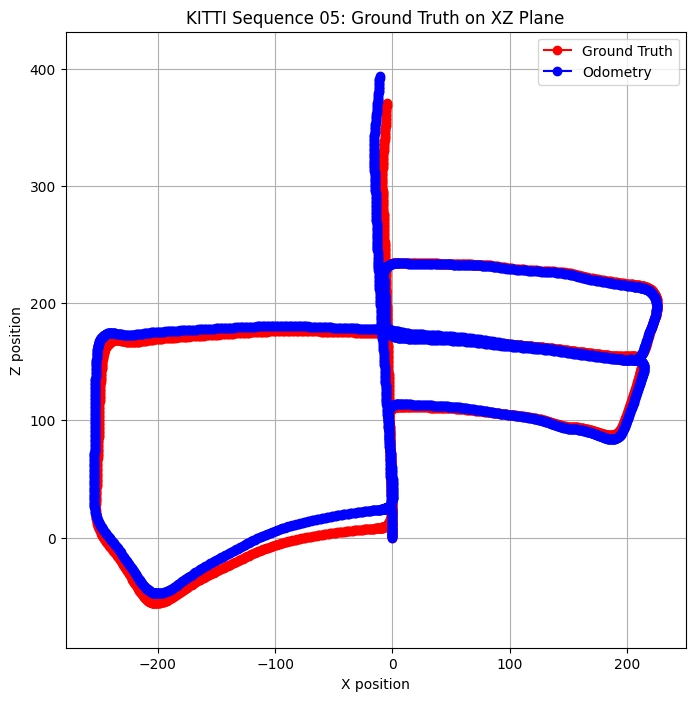

In [12]:
# Plot the Camera Coordinates and the Odometry Coordinates
plot_cam_coords_2d(odometry_poses, gt_poses)